In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

In [2]:
iris = load_iris(as_frame=True)

df = iris.frame.copy()

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

df = df.drop("target", axis=1)

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [3]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [5]:
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


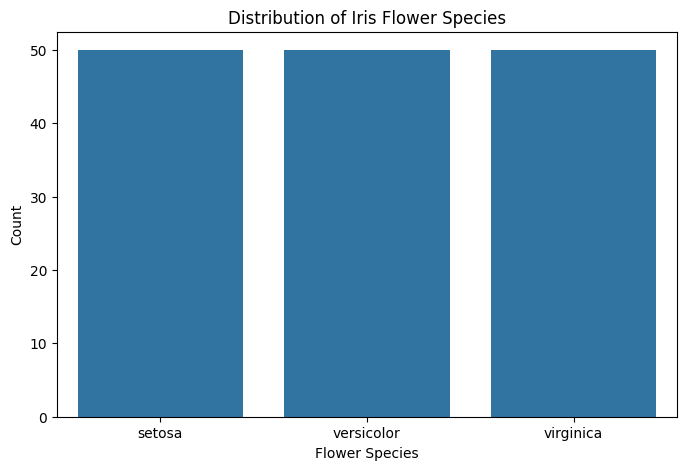

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")

plt.show()

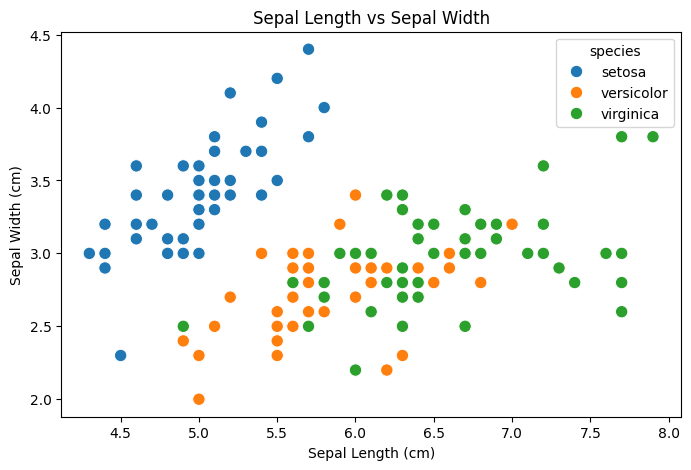

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="sepal width (cm)",
    hue="species",
    s=80
)

plt.title("Sepal Length vs Sepal Width")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")

plt.show()

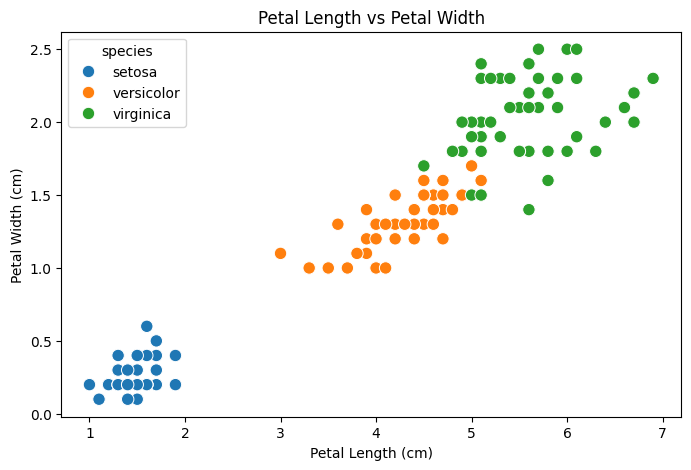

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()

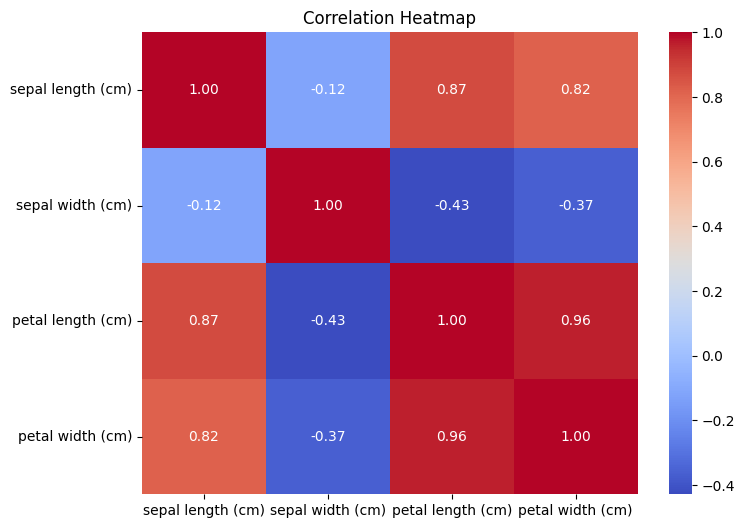

In [9]:
plt.figure(figsize=(8, 6))

correlation = df.drop(
    "species", axis=1
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


In [11]:
# Check missing values
print(df.isnull().sum())

# Separate features and target
X = df.drop("species", axis=1)
y = df["species"]

# Import train_test_split
from sklearn.model_selection import train_test_split

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset size
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
Training Data: (120, 4)
Testing Data: (30, 4)


In [12]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

Decision Tree Model Trained Successfully!
KNN Model Trained Successfully!


In [13]:
y_pred_dt = dt_model.predict(X_test)

print(y_pred_dt)

y_pred_knn = knn_model.predict(X_test)

print(y_pred_knn)

[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor') np.str_('virginica') np.str_('virginica')
 np.str_('virginica') np.str_('versicolor') np.str_('setosa')
 np.str_('setosa') np.str_('setosa') np.str_('versicolor')
 np.str_('versicolor') np.str_('virginica') np.str_('setosa')
 np.str_('virginica') np.str_('versicolor') np.str_('versicolor')
 np.str_('virginica') np.str_('virginica') np.str_('versicolor')
 np.str_('setosa') np.str_('virginica') np.str_('setosa')]
[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor') np.str_('virginica') np.str_('virginica')
 np.str_('virginica') np.str_('versicolor') np.str_('setosa')
 np.str_('setosa') np.str_('setosa') np.str_('versicolor')
 np.str_('

In [14]:
from sklearn.metrics import accuracy_score

In [15]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [16]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 100.0 %


In [17]:
if dt_accuracy > knn_accuracy:
    print("Decision Tree performs better.")
elif knn_accuracy > dt_accuracy:
    print("KNN performs better.")
else:
    print("Both models perform equally.")

KNN performs better.


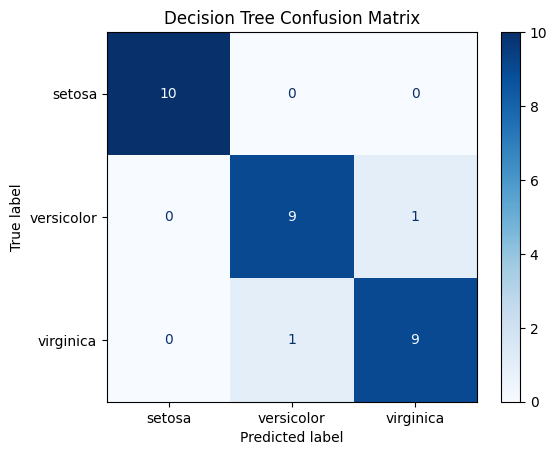

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_dt)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dt_model.classes_
)

display.plot(cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [19]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [20]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

In [21]:
prediction = dt_model.predict(new_flower)

print("Predicted Flower Species:", prediction[0])

Predicted Flower Species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [22]:
prediction = knn_model.predict(new_flower)

print("Predicted Flower Species:", prediction[0])

Predicted Flower Species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [23]:
import joblib

In [24]:
joblib.dump(dt_model, "iris_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [25]:
joblib.dump(knn_model, "iris_knn_model.pkl")

print("KNN Model Saved Successfully!")

KNN Model Saved Successfully!


In [26]:
from google.colab import files

files.download("iris_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
files.download("iris_knn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
df.to_csv("iris_dataset.csv", index=False)

files.download("iris_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>